In [5]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from config import DATA, OUT

df = pd.read_csv(OUT / "metadata_flagged.csv")
kept = df[df["keep"]].copy()

print(f"All images: {len(df)}")
print(f"Total kept: {len(kept)} | Items: {(kept['role']=='item').sum()} | Context: {(kept['role']=='context').sum()}")

All images: 13033
Total kept: 4402 | Items: 4187 | Context: 215


In [6]:
print(df["reason"].replace("", "kept").value_counts())

funnel = pd.crosstab(df["label"], df["reason"].replace("", "kept"), margins=True)
funnel

reason
exact_duplicate    8600
near_duplicate       23
label_conflict        8
Name: count, dtype: int64


reason,exact_duplicate,label_conflict,near_duplicate,All
label,,,,
bed,2,2,0,4
chair,2860,2,14,2876
dining_table,4,2,0,6
sofa,0,2,1,3
table,2862,0,2,2864
wardrobe,2872,0,6,2878
All,8600,8,23,8631


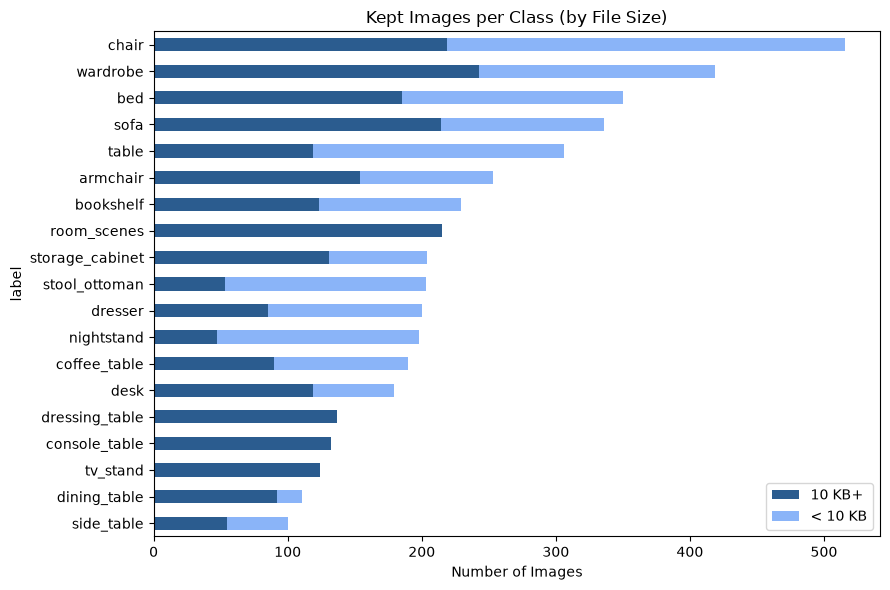

Largest class / smallest class = 5.2x


In [7]:
ct = pd.crosstab(kept["label"], kept["small_kb"]).reindex(columns=[False, True], fill_value=0)
ct.columns = ["10 KB+", "< 10 KB"]
ct.loc[ct.sum(axis=1).sort_values().index].plot(
    kind="barh", stacked=True, figsize=(9, 6), color=["#2b5c8f", "#8ab4f8"]
)
plt.title("Kept Images per Class (by File Size)")
plt.xlabel("Number of Images")
plt.tight_layout()
plt.show()

counts = kept[kept["role"] == "item"]["label"].value_counts()
print(f"Largest class / smallest class = {counts.max() / counts.min():.1f}x")

In [8]:
src_ct = pd.crosstab(kept["label"], kept["source"], margins=True)
display(src_ct)
display(pd.crosstab(kept["label"], kept["source"], normalize="index").round(2))

source,dataset_a,dataset_b,dataset_c,All
label,,,,
armchair,0,253,0,253
bed,0,300,50,350
bookshelf,0,229,0,229
chair,127,286,103,516
coffee_table,0,190,0,190
console_table,0,132,0,132
desk,0,179,0,179
dining_table,0,0,111,111
dresser,0,200,0,200


source,dataset_a,dataset_b,dataset_c
label,,,
armchair,0.00,1.00,0.00
bed,0.00,0.86,0.14
bookshelf,0.00,1.00,0.00
chair,0.25,0.55,0.20
coffee_table,0.00,1.00,0.00
console_table,0.00,1.00,0.00
desk,0.00,1.00,0.00
dining_table,0.00,0.00,1.00
dresser,0.00,1.00,0.00


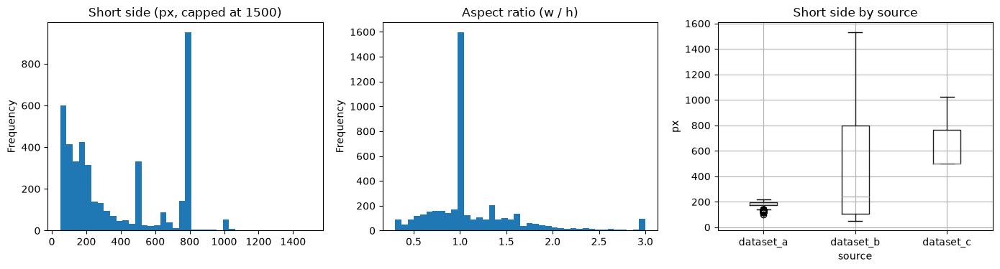

Tiny (<64 px short side): 288 | Small file (<10 KB): 1865


In [9]:
kept["aspect"] = kept["w"] / kept["h"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
kept["short_side"].clip(upper=1500).plot(kind="hist", bins=40, ax=axes[0], title="Short side (px, capped at 1500)")
kept["aspect"].clip(0.3, 3).plot(kind="hist", bins=40, ax=axes[1], title="Aspect ratio (w / h)")
kept.boxplot(column="short_side", by="source", ax=axes[2])
axes[2].set_title("Short side by source")
axes[2].set_ylabel("px")
plt.suptitle("")
plt.tight_layout()
plt.show()

print("Tiny (<64 px short side):", int(kept["tiny_px"].sum()), "| Small file (<10 KB):", int(kept["small_kb"].sum()))

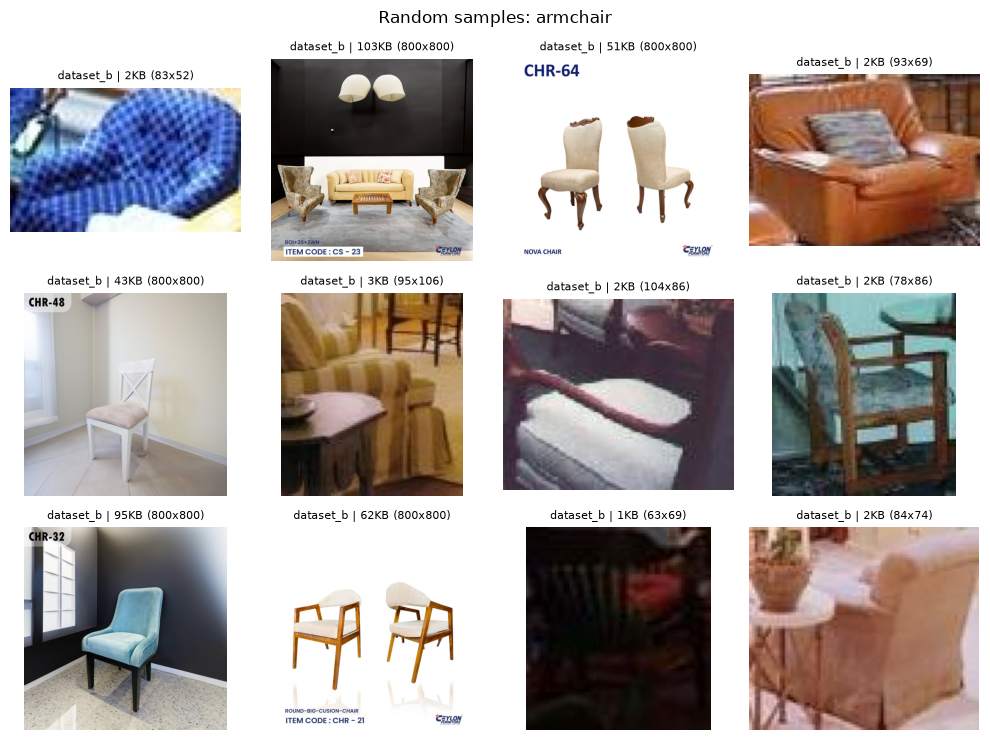

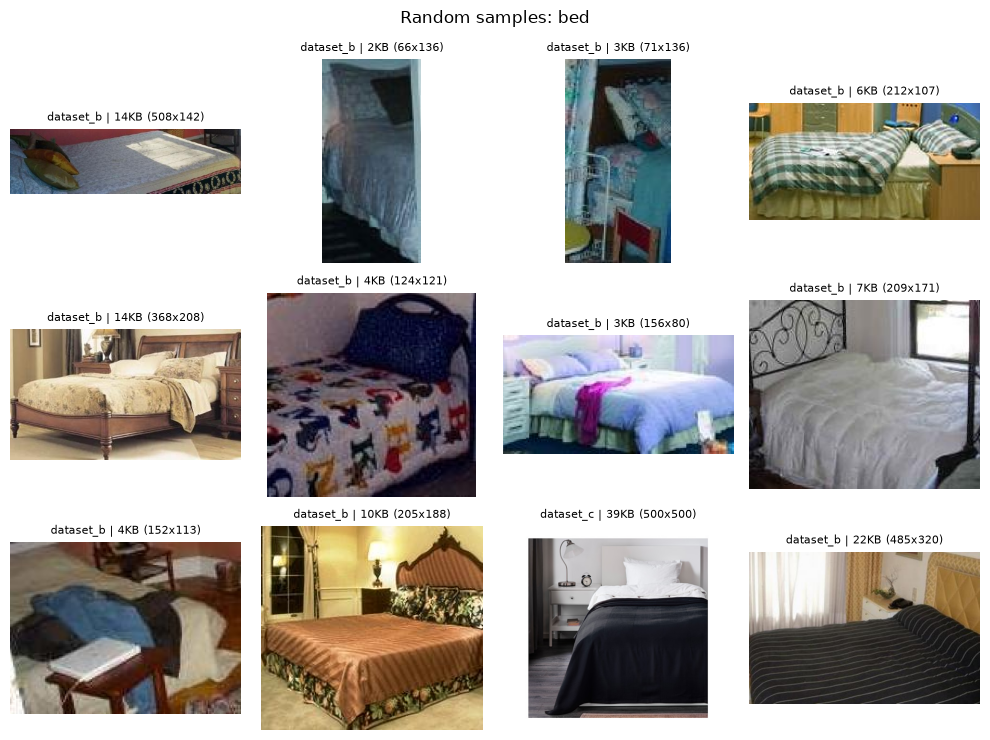

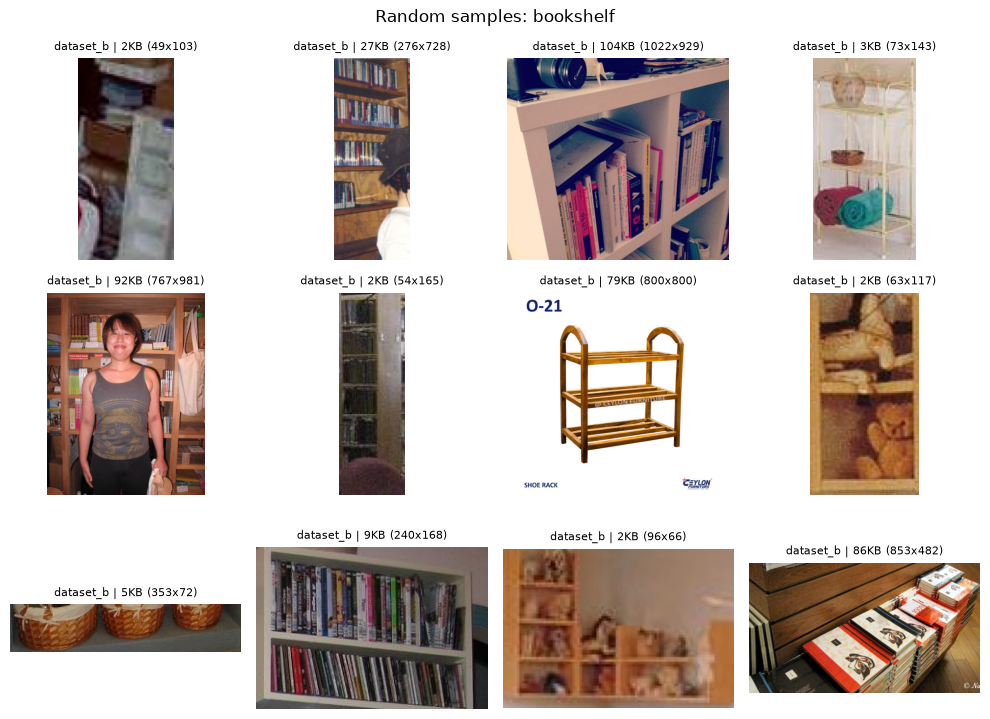

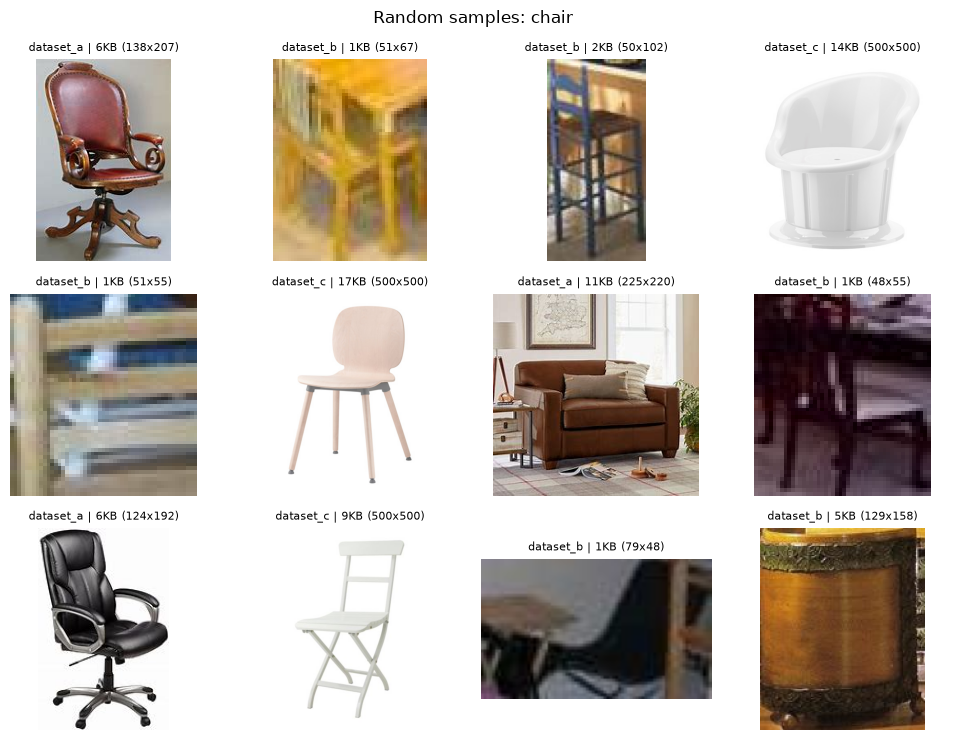

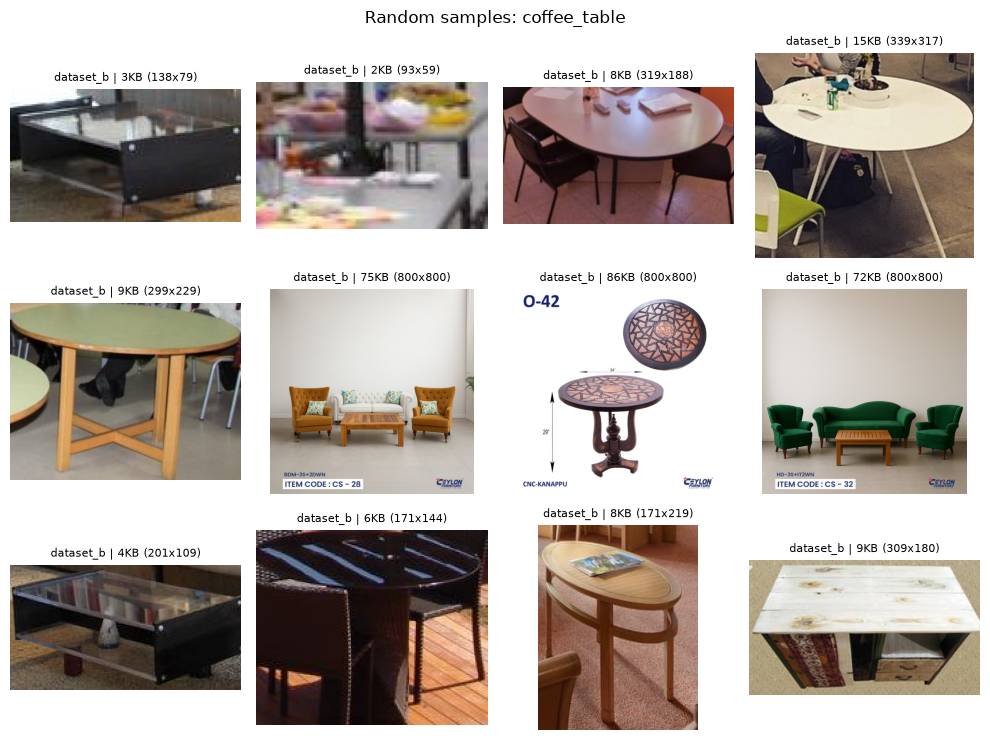

...

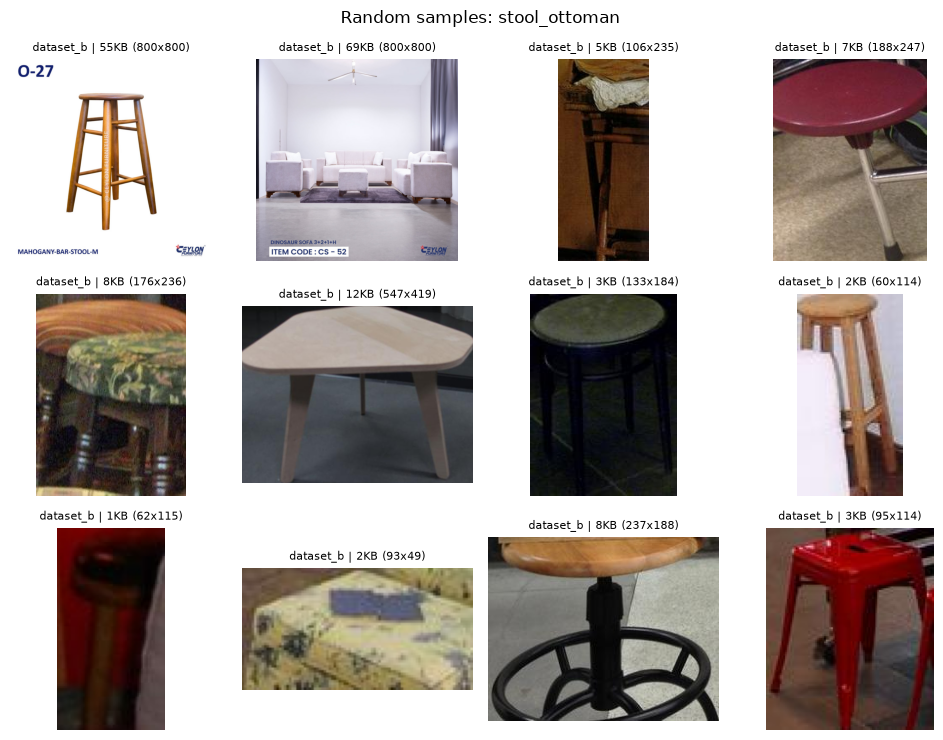

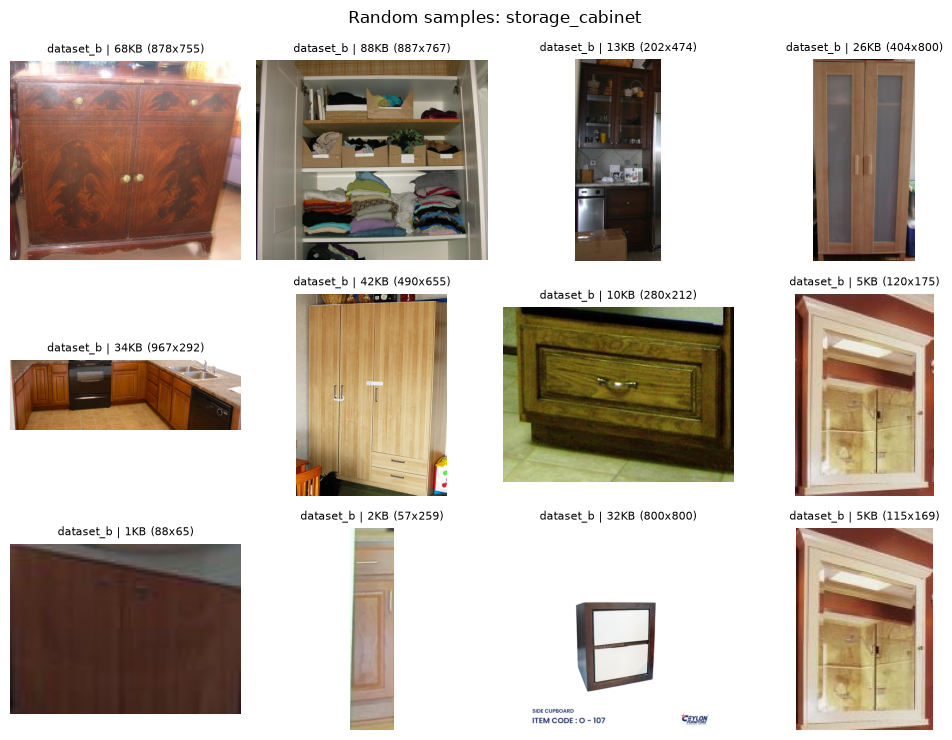

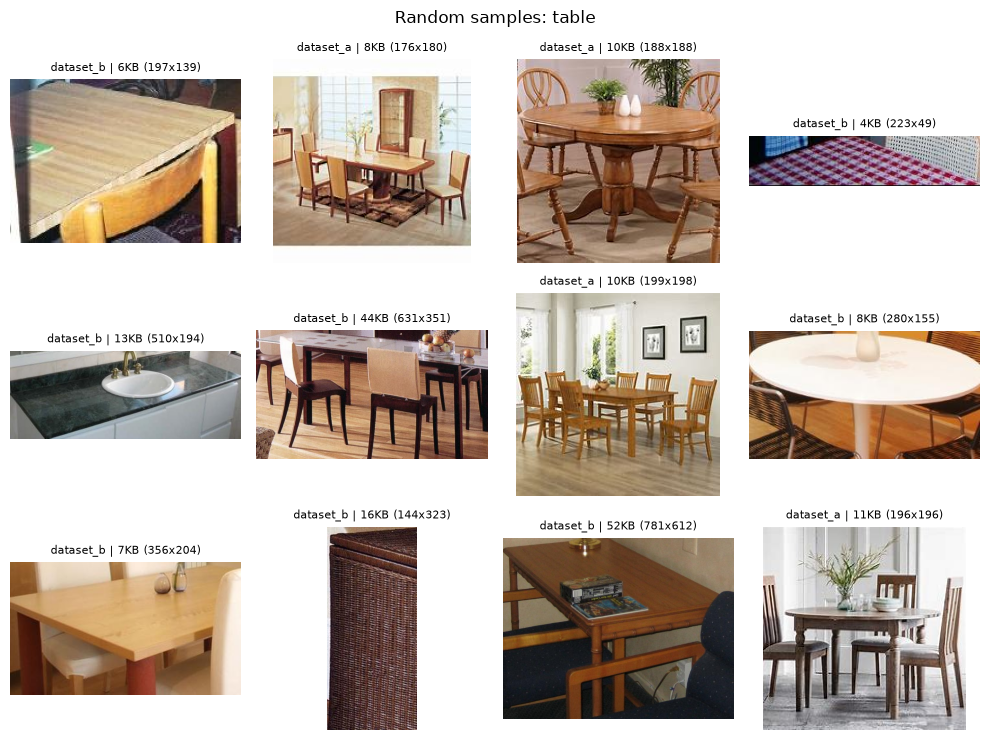

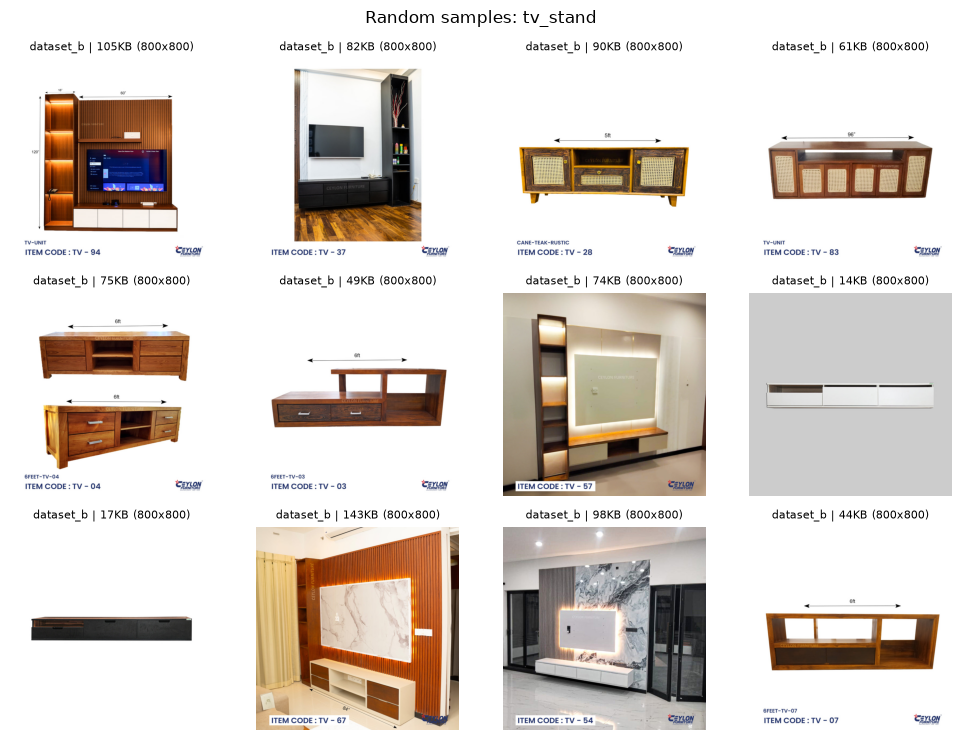

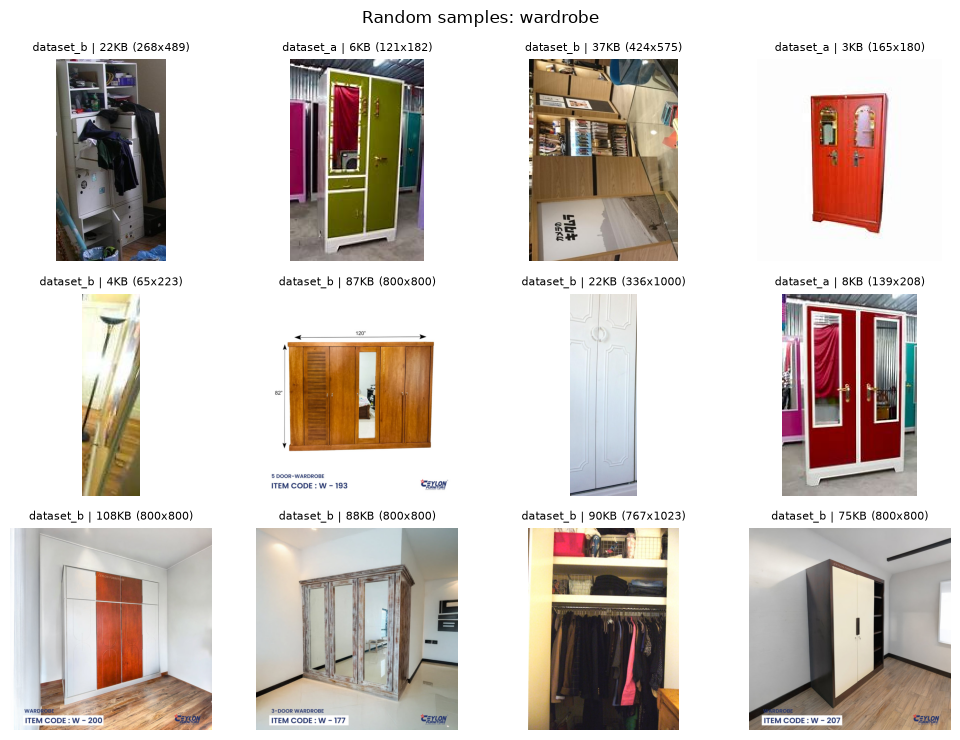

In [10]:
def show_samples(label_name, n=12, cols=4):
    sub = kept[kept["label"] == label_name]
    sample = sub.sample(min(n, len(sub)), random_state=42)
    rows = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
        with Image.open(DATA / row["rel"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{row['source']} | {row['kb']:.0f}KB ({row['w']}x{row['h']})", fontsize=8)
    plt.suptitle(f"Random samples: {label_name}", fontsize=12)
    plt.tight_layout()
    plt.show()

for label in sorted(kept["label"].unique()):
    show_samples(label)

clip_pred
multi_item_collage_poster      421
blurry_fabric_or_wall_crop     334
kitchen_sink_or_stove           93
piles_of_clothes_or_clutter     75
bathroom_mirror_or_vanity       49
electronics_or_laptop           24
person                          21
human_portrait                   4
Name: count, dtype: int64


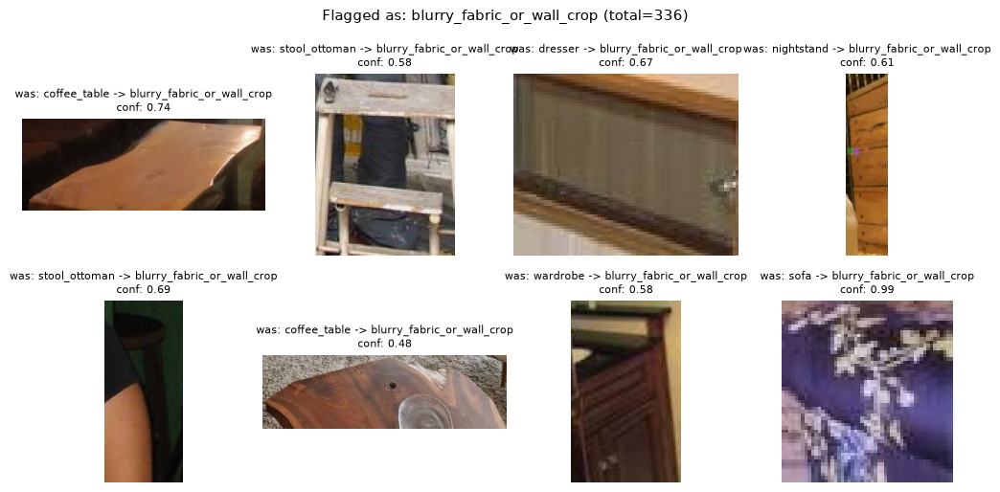

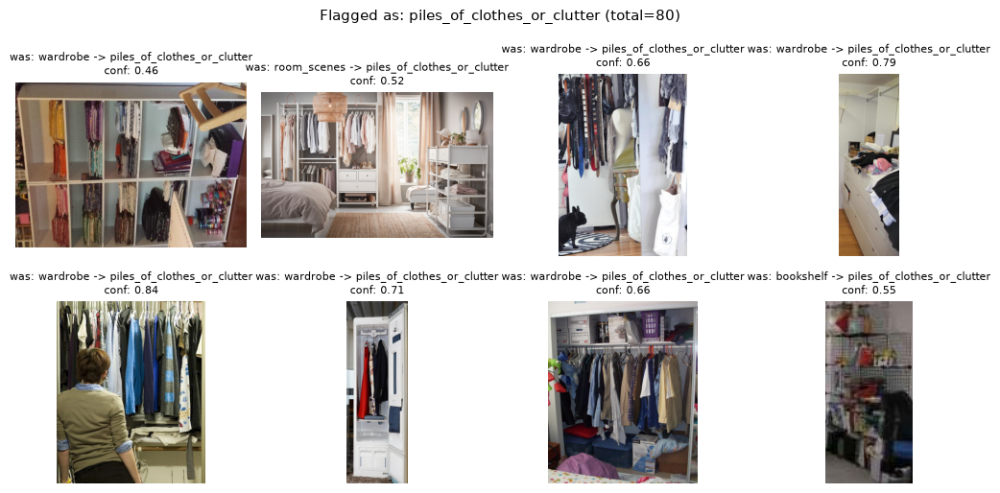

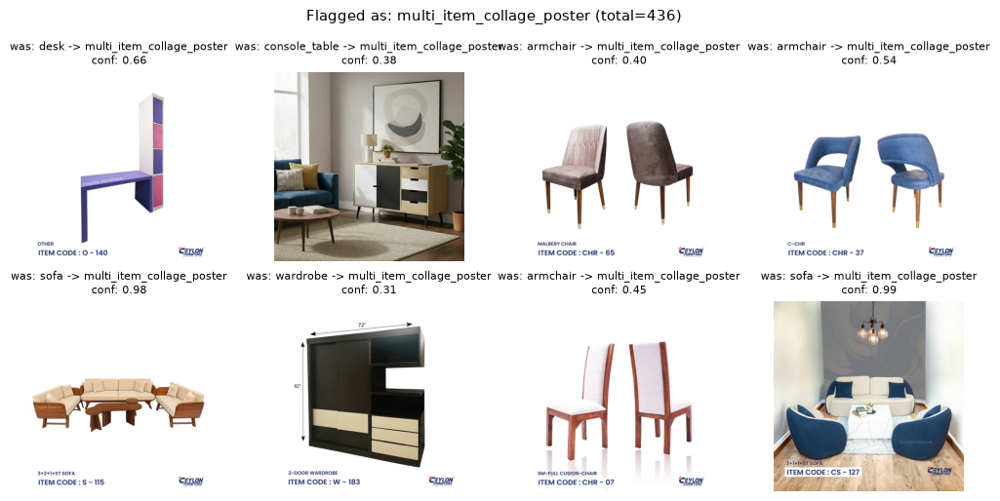

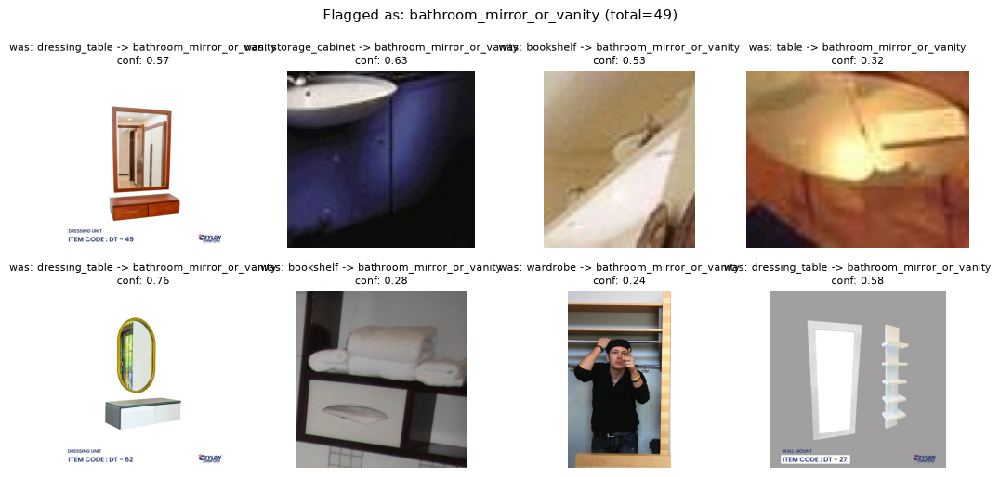

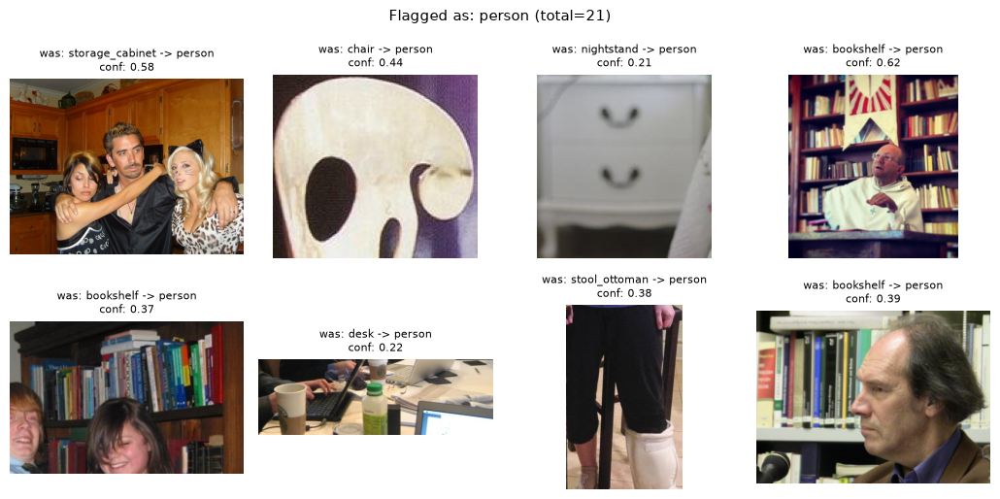

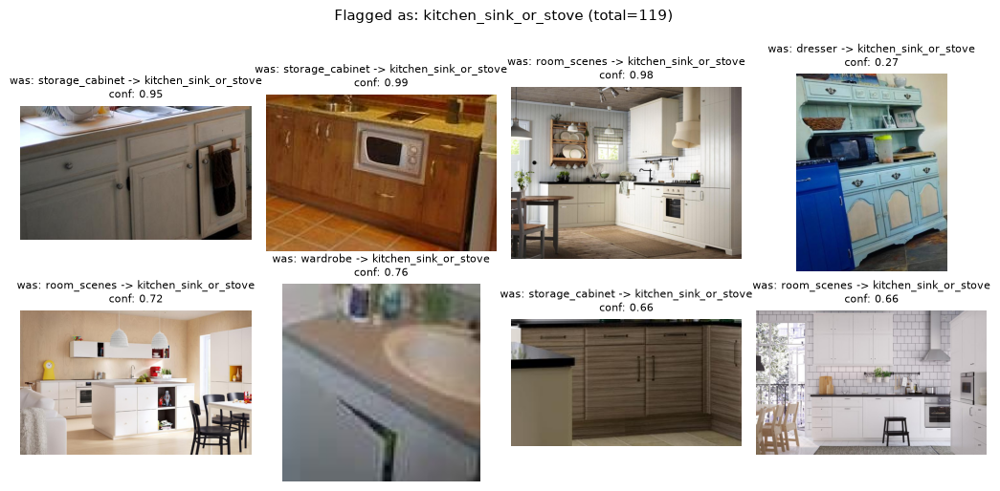

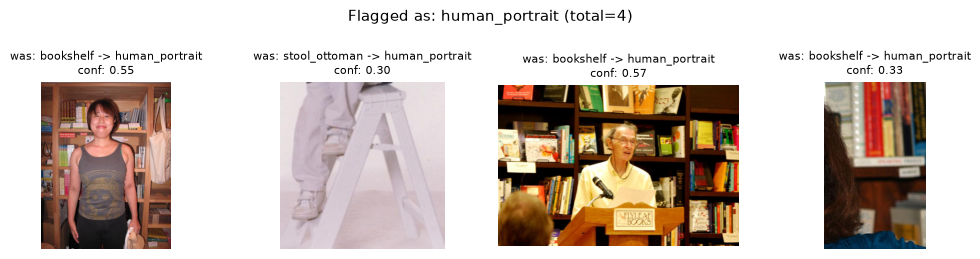

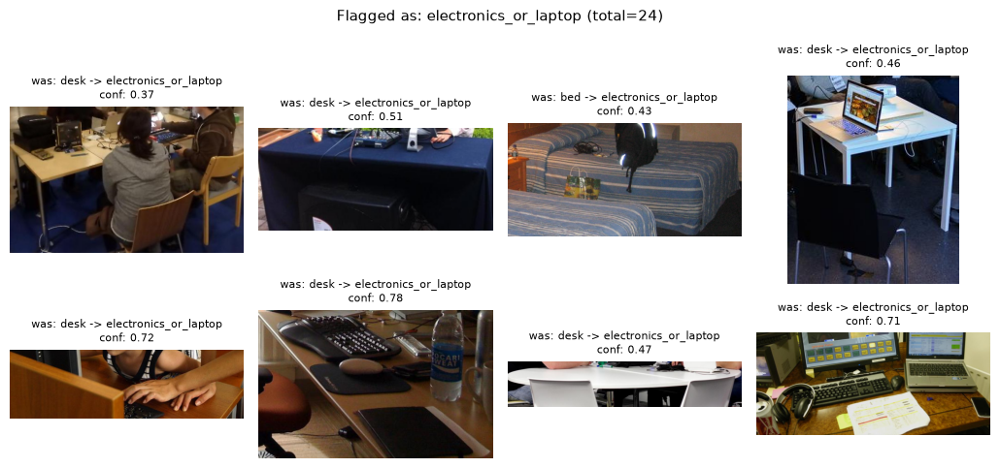

In [11]:
clip_df = pd.read_csv(OUT / "metadata_clip.csv")
print(clip_df[clip_df["is_junk"]]["clip_pred"].value_counts())

def show_flagged(sub, title, n=8, cols=4):
    if len(sub) == 0:
        print("Nothing to show for", title)
        return
    sample = sub.sample(min(n, len(sub)), random_state=42)
    rows = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.6, rows * 2.6))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
        with Image.open(DATA / row["rel"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"was: {row['label']} -> {row['clip_pred']}\nconf: {row['clip_conf']:.2f}", fontsize=8)
    plt.suptitle(f"{title} (total={len(sub)})", fontsize=11)
    plt.tight_layout()
    plt.show()

for jtype in clip_df[clip_df["is_junk"]]["clip_pred"].unique():
    show_flagged(clip_df[clip_df["clip_pred"] == jtype], f"Flagged as: {jtype}")

Total disagreements: 952
clip_pred        armchair  bed  bookshelf  chair  coffee_table  console_table  \
label                                                                           
armchair                0    1          0     26             0              1   
bed                     1    0          0      0             0              2   
bookshelf               1    0          0      0             0              0   
chair                  87    0          0      0             0              4   
coffee_table            0    0          0      0             0             15   
console_table           0    0          0      1             0              0   
desk                    2    0          1      1             1              5   
dining_table            0    0          0      0             0              4   
dresser                 1    1          0      0             0              5   
dressing_table          0    0          0      0             0             11   
nig

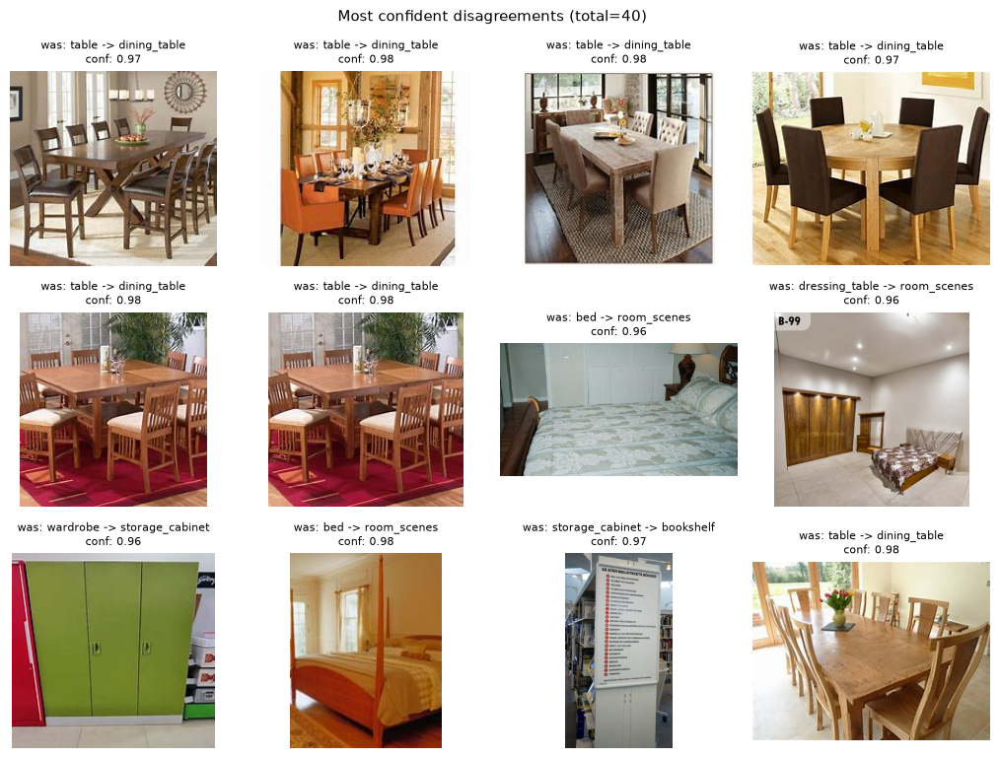

In [12]:
dis = clip_df[clip_df["disagree"]]
print("Total disagreements:", len(dis))
print(pd.crosstab(dis["label"], dis["clip_pred"]))
show_flagged(dis.sort_values("clip_conf", ascending=False).head(40), "Most confident disagreements", n=12)